# **LLMs for psycholinguists  (Part 2)**

- Part 0: &nbsp; Preparation
- Part 1: &nbsp; Basics
- **Part 2: &nbsp; Surprisals for stimuli of controlled experiments**  &nbsp; *<- this notebook*
- Part 3: &nbsp; Surprisals for large-scale naturalistic corpus data
- Part 4: &nbsp; Attention scores

In Part 2, we will see how to get LM surprisal values for the stimuli of controlled psycholinguistic experiments. Typically, the stimuli contain a set of short sentences (at least short enough for LMs). 

In this tutorial, we will use the stimuli from the Experiment 1 of Dillon et al. (2013) [*Contrasting intrusion profiles for agreement and anaphora: Experimental and modeling evidence*](https://doi.org/10.1016/j.jml.2013.04.003). We will get the surprisal for each word of each experimental sentence given the word's proceeding context.

You can download the stimuli data [here](https://github.com/weijiexu-charlie/LLM4Psycholinguists).

#### **The general pipeline:**

![The general pipeline](https://cdn.jsdelivr.net/gh/weijiexu-charlie/LLM4Psycholinguists@main/img/llm_pipeline.svg)


In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

# Pick the fastest available device
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():  # Apple Silicon if you are using MacBook with M1/M2 chip
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: mps


In [2]:
# Initialize model, we will use GPT-2 small for this tutorial.
model = AutoModelForCausalLM.from_pretrained("gpt2")
# model = AutoModelForCausalLM.from_pretrained("gpt2-large") # you can also use larger models

model = model.eval().to(device)
tokenizer = AutoTokenizer.from_pretrained("gpt2")

## **1. Load and preprocess stimuli**

### **1.1 A glimpse into the stimuli**

We first load the stimuli. There are 48 items in this stimuli set, each of which has 8 conditions in a 2x2x2 design:
- **Dependency Type:** &nbsp; agreement vs. reflexives
- **Grammaticality:** &nbsp; grammatical vs. ungrammatical
- **Attractor:** &nbsp; singular vs. plural

Let's print out the first item below. We can see that: 
- Columns ["Item", "Condition"] uniquely identify an experimental sentence.

- Each sentence is relatively short, which means that LMs can process one sentence as a whole without the need to split the sentence. If you notice that the sentence/paragraph is very long, we may need to use an approach other than the one introduced in the current notebook (see Part 3).

In [3]:
# You can adjust the file path to point to the location of the DillonEtAl2013_Experiment1.csv
stimuli_df = pd.read_csv("data/DillonEtAl2013/DillonEtAl2013_Experiment1.csv")
stimuli_df.head(8) # first item

,Item,Condition,Dep,Gram,Attr,Crit_region,Sentence
0,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...
1,1,b,agreement,grammatical,plural,11,The tall nurse who cared for the elderly widow...
2,1,c,agreement,ungrammatical,singular,11,The tall nurse who cared for the elderly widow...
3,1,d,agreement,ungrammatical,plural,11,The tall nurse who cared for the elderly widow...
4,1,e,reflexives,grammatical,singular,12,The tall nurse who cared for the elderly widow...
5,1,f,reflexives,grammatical,plural,12,The tall nurse who cared for the elderly widow...
6,1,g,reflexives,ungrammatical,singular,12,The tall nurse who cared for the elderly widow...
7,1,h,reflexives,ungrammatical,plural,12,The tall nurse who cared for the elderly widow...


### **1.2 Tokenization**

#### **Text units in behavioral data**

The stimuli DataFrame currently has a column of sentences. But what we need is the surprisal for each word. So we first split each sentence into separate words, so each row represents a single word. Sometimes the stimuli file is already organized word-by-word, in which case you can skip this step.

More generally, we want the text at each row to align with the text units (e.g., words, reading-time regions) that experimentalists record behavioral measures on.

In [4]:
def get_stimuli_words(stimuli_df):
    '''
    Split behavioral stimuli sentences into individual words.
    Returns a DataFrame with one row per word.
    '''
    words_df = (
        stimuli_df.assign(Word=stimuli_df["Sentence"].str.split()) # each sentence becomes a list of words
          .explode("Word") # one row per word
          .reset_index(drop=True)
    )
    # Word position within each sentence, counting from 1
    words_df["Word_id"] = words_df.groupby(["Condition", "Item"]).cumcount() + 1
    return words_df

words_df = get_stimuli_words(stimuli_df)
words_df.head(16)   # first 16 rows (the first sentence)

,Item,Condition,Dep,Gram,Attr,Crit_region,Sentence,Word,Word_id
0,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,The,1
1,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,tall,2
2,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,nurse,3
3,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,who,4
4,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,cared,5
5,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,for,6
6,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,the,7
7,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,elderly,8
8,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,widow,9
9,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,definitely,10


#### **Tokenization for LMs**

As we've seen in Part 1, LMs sometimes tokenize texts into subwords. So before we run LMs, we need to tokenize our stimuli using the LM's tokenizer initialized at the beginning of this notebook.

The same sentence above after tokenization is printed below. You can see that there is one more row, because LM tokenization splits the last word "shifts." into 2 tokens, one is the word itself "shifts" and the other is the punctuation.

**Note 1:** *Tokenization on each word separately instead of on the entire sequence is probably not the most efficient way to tokenize texts. But since most of the time as psycholinguists we are not dealing with gigantic stimuli text, we should be fine with the current method, which is simple and intuitive. The result would be the same for GPT-2 and Pythia tokenizer. But be careful that other models may use a different tokenization scheme, in which case you may need to tokenize the stimuli in a different way.*

**Note2:** *The default tokenization of GPT-2 could be problematic for psycholinguistics research (see [Oh & Schuler, 2024](https://aclanthology.org/2024.emnlp-main.202/)). But let's just use the default tokenization here to keep this tutorial simple.*

In [5]:
def tokenize_words(words_df, tokenizer):
    '''
    Tokenize each sentence for the LM and map every token back to its word.
    Returns a new token-level DataFrame (one row per token); words_df is not modified.
    '''
    tokens_df = words_df.copy()
    tokens_df.insert(0, "global_word_id", tokens_df.index.values)
    tokens_df["hftoken"] = tokens_df["Word"].apply(lambda x: tokenizer.tokenize(" " + str(x)))
    tokens_df = tokens_df.explode("hftoken", ignore_index=True)
    tokens_df["token_id"] = tokens_df["hftoken"].apply(tokenizer.convert_tokens_to_ids)
    return tokens_df

tokens_df = tokenize_words(words_df, tokenizer)
tokens_df.head(17)  # first 17 rows (the first sentence)

,global_word_id,Item,Condition,Dep,Gram,Attr,Crit_region,Sentence,Word,Word_id,hftoken,token_id
0,0,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,The,1,ĠThe,383
1,1,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,tall,2,Ġtall,7331
2,2,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,nurse,3,Ġnurse,15849
3,3,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,who,4,Ġwho,508
4,4,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,cared,5,Ġcared,19951
5,5,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,for,6,Ġfor,329
6,6,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,the,7,Ġthe,262
7,7,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,elderly,8,Ġelderly,13830
8,8,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,widow,9,Ġwidow,27075
9,9,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,definitely,10,Ġdefinitely,4753


## **2. Extracting surprisals from LMs (illustrated step by step)**

In this section, I will show step-by-step how to extract surprisals from LMs for our stimuli. I will put things together into one big function later in Section 3.

### **2.1 Batching and padding**

We are going to process our stimuli sentence in batches: the model processes multiple sentences simultaneously. Therefore, what we pass into the model is a matrix, each vector representing a sentence. In fact, for `AutoModelForCausalLM`, the model expects its input to have a batch dimension, even if you only have 1 sentence to process. Processing several sentences at once is also much faster.

Batching requires each row in the input matrix to have the same length. But usually, sentences in a batch are of different length in terms of token number. So we need to add some fake tokens for shorter sentences within a batch:

$$
X_{\text{input}} =
\begin{bmatrix}
\texttt{The} & \texttt{Ġtall} & \texttt{Ġnurse} & \texttt{Ġwas} & \texttt{Ġtired} & \texttt{.} \\
\texttt{The} & \texttt{Ġnurse} & \texttt{Ġwas} & \texttt{Ġtired} & \texttt{.} & \texttt{[PAD]} \\
\texttt{The} & \texttt{Ġnurse} & \texttt{Ġslept} & \texttt{.} & \texttt{[PAD]} & \texttt{[PAD]}
\end{bmatrix}
\quad
\begin{matrix}
\leftarrow \text{sentence 1} \\
\leftarrow \text{sentence 2} \\
\leftarrow \text{sentence 3}
\end{matrix}
$$

These fake tokens are `pad`. Importantly, they need to be added to the right, so they don't change the preceding context of real words. 

Let's define of batch size of 4 (4 sentences processed simultaneously), and build a input matrix for this batch with padding:

In [6]:
batch_size = 4

text_groups = list(tokens_df.groupby(["Item", "Condition"], sort=False))

# GPT-2 does not have a pad token, so we use the EOS token as the pad value. 
# If the tokenizer has a pad token, we use that instead.
pad_value = tokenizer.eos_token_id
if tokenizer.pad_token_id is not None:
    pad_value = tokenizer.pad_token_id

batch = text_groups[0:0 + batch_size]

token_lists = [group['token_id'].tolist() for _, group in batch] # list of tokens of batch size

max_len = max(len(x) for x in token_lists) # the maximal length of the sentences in the batch

# tensor of pad values of the shape (batch_size, max_len)
inputs = torch.full((len(token_lists), max_len), pad_value, dtype=torch.long, device=device)

attention_mask = torch.zeros(len(token_lists), max_len, dtype=torch.long, device=device)

for b, token_list in enumerate(token_lists):
    inputs[b, :len(token_list)] = torch.tensor(token_list, dtype=torch.long, device=device)
    attention_mask[b, :len(token_list)] = 1

Before we move on, let's do some sanity check for the input matrix we just constructed. As shown below, the input is of the size 4 x 18, which means that there are 4 sentences in this batch, and the longest sentence within this batch has 18 tokens.

In [7]:
inputs.shape  # (batch_size, max_len)

torch.Size([4, 18])

We can also see what's inside of this input matrix. There are four vectors, each one is a sequence of tokens for a sentence. Note that Sentence 1 and 3 has a 50256 token at the end: this is the EOS token of GPT-2, which we used as the pad. Before that is the token 13, which corresponds to the period.

In [8]:
inputs

tensor([[  383,  7331, 15849,   508, 19951,   329,   262, 13830, 27075,  4753,
           373, 18416,   284,   670,   890, 15381,    13, 50256],
        [  383,  7331, 15849,   508, 19951,   329,   262, 13830,  9214,  1666,
          4753,   373, 18416,   284,   670,   890, 15381,    13],
        [  383,  7331, 15849,   508, 19951,   329,   262, 13830, 27075,  4753,
           547, 18416,   284,   670,   890, 15381,    13, 50256],
        [  383,  7331, 15849,   508, 19951,   329,   262, 13830,  9214,  1666,
          4753,   547, 18416,   284,   670,   890, 15381,    13]],
       device='mps:0')

We've also specified an attention-mask matrix, which is printed below. It has the same shape as the input matrix, and tells the model whether it should block the attention to any token. You can see that the first and the third sentence has a 0 at the end. This tells the model that these two token positions are for a fake `PAD` token, so the model can ignore it.

In [9]:
attention_mask

tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]],
       device='mps:0')

#### **Important!**

The length of the input should **NOT** exceed the model's maximal sequence length, otherwise the model will fail. 

Ideally, Huggingface would flag an error if this happens. But sometimes it won't be able to reliably detect this error, in which case the model will silently fail, producing incorrect results. So to be on the safe side, let's explicitly check our input length using the following code (no issue for our current set of stimuli). 

If there's a sequence length issue, we need to switch to another approach to generate surprisals, which I will introduce in Part 3 of this tutorial.

In [10]:
# the maximal sequence length allowed by the model (e.g., 1024 for GPT-2):
max_pos = getattr(model.config, "n_positions", None) or getattr(model.config, "max_position_embeddings", None)

# raise an error if the maximal length of the sentences exceeds the model's maximal sequence length:
if max_pos is not None and max_len > max_pos:
    raise IndexError(f"Sequence too long: {max_len} > {max_pos}. Use sliding windows instead.")

### **2.2 Let's now run the model!**

When running the model, make sure to use `with torch.no_grad`. It turns off gradient tracking, which is only needed for training, so the model runs faster and uses less memory.

In [11]:
with torch.no_grad():
    output = model(inputs, attention_mask=attention_mask)

Now the model has processed our 4 input sentences, and the result is stored in `output`.

#### **Logit scores**

We will take the logits from this output using `output.logits`.

In [12]:
output.logits.shape  # (batch_size, max_len, vocab_size)

torch.Size([4, 18, 50257])

The structure of this logits matrix is basically the same as what we've seen in Part 1, except that now we have an additional dimension because of batching:
- The first dimension of `output.logits` is the batch dimension (4 sentences in this batch).

Each element within `output.logits` is the logits of a sentence. In this example, it is of the size 18 x 50257:
- The model generates a prediction at each one of the 18 token positions in the sentence.
- Each prediction is a vector of logit scores $\mathbf{z}$ across all possible tokens in the model's vocabulary of size V (there are 50257 possible tokens in GPT-2).

In [13]:
output.logits[0].shape  # (max_len, vocab_size)

torch.Size([18, 50257])

The structure of this matrix is shown below. Each row corresponds to a token position in the sentence, and is a vector of logit scores over the vocabulary.

$$
\mathrm{logits} =
\begin{array}{r}
\scriptstyle \texttt{The} \\
\scriptstyle \texttt{Ġnurse} \\
\scriptstyle \texttt{Ġslept} \\
\scriptstyle \texttt{.}
\end{array}
\!\!
\overset{
\begin{matrix}
% \scriptstyle \texttt{!} & \scriptstyle \cdots & \scriptstyle \texttt{Ġnurse} & \scriptstyle \cdots & \scriptstyle \texttt{Ġslept} & \scriptstyle \cdots & \scriptstyle \texttt{.} & \scriptstyle \cdots
\scriptstyle \texttt{50257 possible tokens in vocab}
\end{matrix}
}{
\begin{bmatrix}
z_{1,1} & z_{1,2} & z_{1,3} & \cdots & z_{1, V} \\
z_{2,1} & z_{2,2} & z_{2,3} & \cdots & z_{2, V} \\
z_{3,1} & z_{3,2} & z_{3,3} & \cdots & z_{3, V} \\
z_{4,1} & z_{4,2} & z_{4,3} & \cdots & z_{4, V}
\end{bmatrix}
}
$$

This is the logit score matrix of one sentence. Since we have 4 sentences in our batch, `output.logits` is simply a stack of 4 matrices like this.

#### **Logit scores to log probabilities**

We turn logit scores into probabilities using softmax function.

More specifically, what we want is log probabilities. So instead of using `softmax()`, we will use `log_softmax()` in pytorch, which is often more reliable. Also, we want to take softmax over the vocabulary, which is the last dimension in `output.logits`, so we specify `dim=-1`.

As you can see below, `log_probs` has the same shape as `output.logits`.

In [14]:
log_probs = output.logits.log_softmax(dim=-1).cpu()  # shape: (batch_size, n_tokens, vocab_size)
log_probs.shape

torch.Size([4, 18, 50257])

We can also get the entropy at each position, which is another useful quantity for psycholinguistics.

In [15]:
entropies = torch.distributions.Categorical(logits=log_probs).entropy().cpu()
entropies.shape

torch.Size([4, 18])

### **2.3 Token-level surprisal**

Now let's get the surprisal of each token in our input.

Earlier, we've got a log probability distribution at each token position over all possible next token. In other words, each possible next token is associated with a log probability. What we need to do now is to extract the actual next token, and see what's the log probability associated with it.

Consider the second sentence in our input (`inputs[1]` printed below). The first token has id=383, and what the model just gave us above is a log probability distribution over 50257 possible next tokens. From the input, we know that the actual token that follows the first one has id=7331. So we simply extract the 7331th element from the distribution. We can do this for every token position.

![Each position predicts the next token](https://cdn.jsdelivr.net/gh/weijiexu-charlie/LLM4Psycholinguists@main/img/surprisal_1_next_token_shift.svg)

In [16]:
inputs[1]

tensor([  383,  7331, 15849,   508, 19951,   329,   262, 13830,  9214,  1666,
         4753,   373, 18416,   284,   670,   890, 15381,    13],
       device='mps:0')

First we define `target_ids`, which are the IDs of the actual next tokens. 

Notice that it is systematically left-shifted by one token compared to the inputs, since the target token at position t is predicted from probabilities at position t-1. So the sequence length is also 1 token less than the inputs.

In [17]:
# target token at t predicted from logits at t-1, shape: (batch_size, seq_len-1)
target_ids = inputs[:, 1:].cpu()

print("Target token IDs shape:", target_ids.shape)
target_ids

Target token IDs shape: torch.Size([4, 17])


tensor([[ 7331, 15849,   508, 19951,   329,   262, 13830, 27075,  4753,   373,
         18416,   284,   670,   890, 15381,    13, 50256],
        [ 7331, 15849,   508, 19951,   329,   262, 13830,  9214,  1666,  4753,
           373, 18416,   284,   670,   890, 15381,    13],
        [ 7331, 15849,   508, 19951,   329,   262, 13830, 27075,  4753,   547,
         18416,   284,   670,   890, 15381,    13, 50256],
        [ 7331, 15849,   508, 19951,   329,   262, 13830,  9214,  1666,  4753,
           547, 18416,   284,   670,   890, 15381,    13]])

Now we extract each token's log probability based on `target_ids`. But before that, let's check the dimensionality of the two matrices we have:
- `target_ids`: 4 x 17
- `log_probs`: 4 x 18 x 50257

Because of the mismatch of dimensionality, the code below does four things:

1. `log_probs[:, :-1, :]` remove the last token's log probability, since there is no next token after the last one. Recall that after batching, the token position is the second dimension of `log_probs`, so the operation is on the second dimension. After this, `log_probs` will be of size 4 x 17 x 50257.

1. `target_ids[:, :, None]` add one more dimension to `target_ids`, corresponding to the vocab dimension of `log_probs`.

1. The `gather()` function extract the log probability according to target_ids [(documentation)](https://docs.pytorch.org/docs/stable/generated/torch.gather.html). This gives us a matrix of size 4 x 17 x 1.

1. In the end, `squeeze(-1)`remove the vocab dimension, giving us a matrix of size 4 x 17

**Note:** *The model's log probabilities use natural logarithm (base $e$), so surprisals computed from them are in nats. For psycholinguistic studies, we usually report surprisal in bits (base 2). So here we convert log probabilities to have base 2.*

![How the tensor shapes line up](https://cdn.jsdelivr.net/gh/weijiexu-charlie/LLM4Psycholinguists@main/img/surprisal_3_shapes.svg)

In [18]:
# log_probs[:, :-1, :] removes the last token's log_prob distribution, shape: (batch_size, seq_len-1, vocab_size)
# target_ids[:, :, None] add another dimension for vocab_size, shape: (batch_size, seq_len-1, 1) 
token_logps = log_probs[:, :-1, :].gather(
    dim=-1, # along the vocab_size dimension, gather the entry corresponding to the target token id
    index=target_ids[:, :, None]
).squeeze(-1)

token_logps = token_logps / np.log(2)  # convert to bits

print("Token log probabilities shape:", token_logps.shape)
token_logps

Token log probabilities shape: torch.Size([4, 17])


tensor([[-14.6868, -13.8961,  -4.9209,  -8.9572,  -0.0467,  -2.7353,  -6.0894,
         -12.2554, -16.6179,  -4.8952, -12.6177,  -0.1903,  -7.0520,  -7.6674,
          -6.1068,  -2.2016,  -9.0827],
        [-14.6868, -13.8961,  -4.9209,  -8.9572,  -0.0467,  -2.7353,  -6.0894,
         -11.9528,  -1.4370, -17.0042,  -4.9674, -12.4003,  -0.2058,  -7.0235,
          -7.5452,  -6.1985,  -2.1884],
        [-14.6868, -13.8961,  -4.9209,  -8.9572,  -0.0467,  -2.7353,  -6.0894,
         -12.2554, -16.6179, -12.1618, -12.1294,  -0.2274,  -6.8081,  -7.8160,
          -5.8293,  -2.1930,  -9.0057],
        [-14.6868, -13.8961,  -4.9209,  -8.9572,  -0.0467,  -2.7353,  -6.0894,
         -11.9528,  -1.4370, -17.0042, -11.0755, -11.7849,  -0.2323,  -6.7081,
          -7.5286,  -6.0008,  -2.1702]])

The matrix above is our token log probabilities for the 4 sentences in our batch. 

Note that token probabilities here is still one token misaligned. For example, the first element within a row does not correspond to the probability of the first token, but the probability of the second token. We will address this issue below.

### **2.4 Word-level surprisal**

We are now only two steps away from getting the final version word surprisals!

The remaining two issues are:
1. Get rid of the padding we added earlier for batching.

1. Align token log probabilities (which could be subwords) to word log probabilities. 

#### **Deal with padding**

We for loop over each sentence (which as a DataFrame) in the batch. Within each sentence:
1. Get the number of real tokens in this sentence.
1. Create a numpy nan array of the same size of real tokens.
1. Fill in this nan array with token log probabilities, but skipping the first token (there is no preceding context to predict the first token).
1. Take negative to turn log probabilities into surprisals
1. Write token surprisals to sentence DataFrame
1. Do the same thing for entropies, again skipping the first token

In [19]:
batch_result = []

for b, (_, group) in enumerate(batch):
    group = group.copy()
    n = len(group)
    logp_array = np.full(n, np.nan) # shape: (n_tokens)

    # first token logp of a sequence is always nan
    logp_array[1:] = token_logps[b, :n-1].numpy()
    group["token_surprisal"] = -logp_array

    entropy_array = np.full(n, np.nan) # shape: (n_tokens)
    entropy_array[1:] = entropies[b, :n-1].numpy()
    group["token_entropy"] = entropy_array

    batch_result.append(group)

batch_surprisal_df = pd.concat(batch_result, ignore_index=True)

batch_surprisal_df.head(5)

,global_word_id,Item,Condition,Dep,Gram,Attr,Crit_region,Sentence,Word,Word_id,hftoken,token_id,token_surprisal,token_entropy
0,0,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,The,1,ĠThe,383,NaN,NaN
1,1,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,tall,2,Ġtall,7331,14.686807,8.975410
2,2,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,nurse,3,Ġnurse,15849,13.896081,6.142900
3,3,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,who,4,Ġwho,508,4.920880,5.625439
4,4,1,a,agreement,grammatical,singular,11,The tall nurse who cared for the elderly widow...,cared,5,Ġcared,19951,8.957197,6.002800


#### **Align tokenization**

In the last step, we need to align LM's tokenization with the one used in behavioral data, for example matching the tokens with text in the Word column of our stimuli. This is where our previously inserted "global_word_id" column becomes helpful.

If the LM tokenizer splits a word into several tokens, the chain rule tells us that the word's probability is the product of its tokens' probabilities. For example, "shifts." is split into `Ġshifts` and `.`, so given the preceding context $c$:

$$
p(\text{shifts.} \mid c) = p(\text{shifts} \mid c)\; p(\text{.} \mid c, \text{shifts})
$$

Taking the negative log turns this product into a sum, so a word's surprisal is the **sum** of its tokens' surprisals:

$$
S(\text{shifts.}) = S(\text{shifts}) + S(\text{.})
$$

In [20]:
def align_tokenization(token_surp_df):
    '''
    - Surprisal: Reduce token-level surprisals to word-level by summing over tokens that belong to 
        the same word. NaN if any token is NaN (e.g., the first token of a sentence)
    - Entropy: Reduce token-level predictive entropies to word-level by taking the entropy of 
        the first token

    Returns a new DataFrame with tokenization aligned
    '''

    token_cols = ["token_id", "hftoken", "token_surprisal", "token_entropy"]
    word_cols = [c for c in token_surp_df.columns if c not in token_cols + ["global_word_id"]]

    g = token_surp_df.groupby("global_word_id", sort=False)

    aligned_df = g[word_cols].first()     
    aligned_df["hftokens"] = g["hftoken"].agg(list)
    aligned_df["word_surprisal"] = g["token_surprisal"].agg(lambda x: x.sum(skipna=False)) # if any token is NaN, the word surprisal will be NaN
    aligned_df["word_entropy"] = g["token_entropy"].agg(lambda x: x.iloc[0])

    return aligned_df.reset_index(drop=True)

batch_surprisal_aligned = align_tokenization(batch_surprisal_df)


# You can check that the tokenization of "shifts." is now aligned.
batch_surprisal_aligned.iloc[15]

Item                                                              1
Condition                                                         a
Dep                                                       agreement
Gram                                                    grammatical
Attr                                                       singular
Crit_region                                                      11
Sentence          The tall nurse who cared for the elderly widow...
Word                                                        shifts.
Word_id                                                          16
hftokens                                               [Ġshifts, .]
word_surprisal                                             8.308372
word_entropy                                               0.675014
Name: 15, dtype: object

## **3. Putting things together**

Now, let's put all things together into one big function called `surprisal()`. This function will take the preprocessed stimuli DataFrame `words_df` and return a new DataFrame with additional columns for LM surprisals. Make sure that the model and the tokenizer is already initialized before calling this function.

We also need to specify through `groupby_col` what are the columns in the stimuli that uniquely identify a sentence.

I set the default batch size to be 4. But you can also try bigger batch size. It won't make a big difference here because our stimuli set is relatively small, but usually bigger batch size can be faster if you have a big set of sentences to process. If a memory issue occurs, you can always switch to a smaller batch size.

In [21]:
def surprisal(
    model, 
    tokenizer,
    words_df, 
    groupby_col,
    use_nats=False,
    batch_size=4,
    device=device
):
    """
    Get word surprisals and entropies.
    Token surprisals are summed if belonging to the same word.

    Args:
        model: Language model object (e.g., GPT-2)
        tokenizer: tokenizer object corresponding to the model
        words_df: DataFrame containing the words data
        groupby_col: column names to group by for coherent discourse (e.g., ["Item", "Condition"])
        use_nats: whether to use log probabilities in nats (True) or in bits (False)
        batch_size: number of sequences to process simultaneously in a batch
    
    Returns a new DataFrame with word-level surprisals and entropies, aligned with the original words_df.
    """
    model.eval().to(device)

    tokens_df = tokenize_words(words_df, tokenizer)

    if isinstance(groupby_col, str):
        groupby_col = [groupby_col]
    missing = [col for col in groupby_col if col not in tokens_df.columns]
    assert not missing, f"Columns not found in tokens_df: {missing}"

    pad_value = tokenizer.eos_token_id
    if tokenizer.pad_token_id is not None:
        pad_value = tokenizer.pad_token_id
    
    text_groups = list(tokens_df.groupby(groupby_col, sort=False))


    all_out = []

    # loop through the text groups in batches
    for i in range(0, len(text_groups), batch_size):

        batch = text_groups[i:i + batch_size]

        token_lists = [group['token_id'].tolist() for _, group in batch] # list of tokens of batch size
        max_len = max(len(x) for x in token_lists) # the maximal length of the sentences in the batch

        # Check sequence length
        max_pos = getattr(model.config, "n_positions", None) or getattr(model.config, "max_position_embeddings", None)
        if max_pos is not None and max_len > max_pos:
            raise IndexError(f"Sequence too long: {max_len} > {max_pos}. Use sliding windows instead.")
    
        
        # tensor of pad values of the shape (batch_size, max_len)
        inputs = torch.full((len(token_lists), max_len), pad_value, dtype=torch.long, device=device)

        attention_mask = torch.zeros(len(token_lists), max_len, dtype=torch.long, device=device)

        for b, token_list in enumerate(token_lists):
            inputs[b, :len(token_list)] = torch.tensor(token_list, dtype=torch.long, device=device)
            attention_mask[b, :len(token_list)] = 1


        # generating log probability distributions for the batch
        with torch.no_grad():
            output = model(inputs, attention_mask=attention_mask)
            logits = output.logits  # shape: (batch_size, n_tokens, vocab_size)
            log_probs = logits.log_softmax(dim=-1).cpu()  # shape: (batch_size, n_tokens, vocab_size)
            entropies = torch.distributions.Categorical(logits=log_probs).entropy()

        target_ids = inputs[:, 1:].cpu()  # target token at t predicted from logits at t-1, shape: (batch_size, seq_len-1)

        # log_probs[:, :-1, :] removes the last token's log_prob distribution, shape: (batch_size, seq_len-1, vocab_size)
        # target_ids[:, :, None] add another dimension for vocab_size, shape: (batch_size, seq_len-1, 1) 
        token_logps = log_probs[:, :-1, :].gather(
            dim=-1, # along the vocab_size dimension, gather the entry corresponding to the target token id
            index=target_ids[:, :, None]
        ).squeeze(-1)

        if not use_nats:
            token_logps = token_logps / np.log(2)  # convert to bits
            entropies = entropies / np.log(2)

        for b, (_, group) in enumerate(batch):
            group = group.copy()
            n = len(group)
            logp_array = np.full(n, np.nan) # shape: (n_tokens)

            # first token logp of a sequence is always nan
            logp_array[1:] = token_logps[b, :n-1].numpy()
            group["token_surprisal"] = -logp_array

            entropy_array = np.full(n, np.nan) # shape: (n_tokens)
            entropy_array[1:] = entropies[b, :n-1].numpy()
            group["token_entropy"] = entropy_array

            all_out.append(group)


    token_surprisal_df = pd.concat(all_out, ignore_index=True)
    word_surprisal_df = align_tokenization(token_surprisal_df)

    return word_surprisal_df

In [22]:
result = surprisal(
    model=model,
    tokenizer=tokenizer,
    words_df=words_df,
    groupby_col=["Item", "Condition"],
    use_nats=False,
    batch_size=4,
    device=device
)

## **4. Visualize agreement attraction effect**

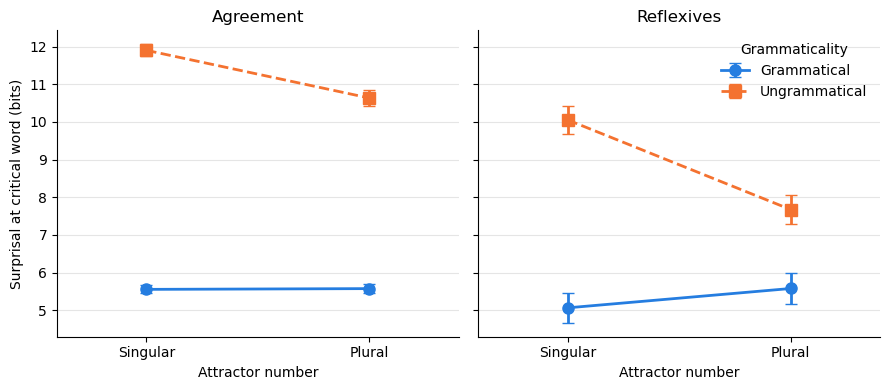

In [23]:
import matplotlib.pyplot as plt

# Keep only the critical word of each sentence
analysis_df = result[result["Word_id"] == result["Crit_region"]].copy()

# Mean and standard error per cell (across the 48 items)
summary = (
    analysis_df.groupby(["Dep", "Gram", "Attr"])["word_surprisal"]
    .agg(mean="mean", se="sem")
    .reset_index()
)

attr_order = ["singular", "plural"]
gram_styles = {   # color + marker + line style, so the conditions don't rely on color alone
    "grammatical":   dict(color="#257de0", marker="o", linestyle="-"),
    "ungrammatical": dict(color="#f47230", marker="s", linestyle="--"),
}

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

for ax, dep in zip(axes, ["agreement", "reflexives"]):
    for gram, style in gram_styles.items():
        d = (summary[(summary["Dep"] == dep) & (summary["Gram"] == gram)]
             .set_index("Attr").loc[attr_order])
        ax.errorbar(range(len(attr_order)), d["mean"], yerr=d["se"],
                    capsize=4, linewidth=2, markersize=8,
                    label=gram.capitalize(), **style)

    ax.set_title(dep.capitalize())
    ax.set_xticks(range(len(attr_order)), [a.capitalize() for a in attr_order])
    ax.set_xlim(-0.4, len(attr_order) - 0.6)
    ax.set_xlabel("Attractor number")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Surprisal at critical word (bits)")
axes[1].legend(title="Grammaticality", frameon=False)
fig.tight_layout()
plt.show()